<a href="https://colab.research.google.com/github/sushant1811/Sushant-kumar/blob/main/EDA_phase1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

In [3]:
#Loading the Dataset
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/school93_98.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully")
print("Rows and Columns:", df.shape)

df.head()

Dataset Loaded Successfully
Rows and Columns: (10668, 19)


,rownames,distid,schid,lunch,enrol,exppp,math4,year,y93,y94,y95,y96,y97,y98,rexpp,found,lenrol,lrexpp,lavgrexpp
0,1,34010,1,39.799999,256.0,2506.0,46.599998,1993,1,0,0,0,0,0,2783.480957,NaN,5.545177,7.931458,NaN
1,2,34010,1,35.000000,248.0,2870.0,44.700001,1994,0,1,0,0,0,0,3108.198486,NaN,5.513429,8.041799,7.988149
2,3,34010,1,36.590000,244.0,4176.0,86.500000,1995,0,0,1,0,0,0,4397.953125,4478.0,5.497168,8.388894,8.230331
3,4,34010,1,40.549999,247.0,4333.0,84.300003,1996,0,0,0,1,0,0,4432.418945,4754.0,5.509388,8.396701,8.392805
4,5,34010,1,49.490002,291.0,3666.0,83.800003,1997,0,0,0,0,1,0,3666.000000,5032.0,5.673323,8.206857,8.306277


In [4]:
#Basic Statistical Analysis
print("Shape of Dataset:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nStatistical Summary Including Categorical Columns:")
print(df.describe(include="all"))

Shape of Dataset:
(10668, 19)

Column Names:
Index(['rownames', 'distid', 'schid', 'lunch', 'enrol', 'exppp', 'math4',
       'year', 'y93', 'y94', 'y95', 'y96', 'y97', 'y98', 'rexpp', 'found',
       'lenrol', 'lrexpp', 'lavgrexpp'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10668 entries, 0 to 10667
Data columns (total 19 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   rownames   10668 non-null  int64  
 1   distid     10668 non-null  int64  
 2   schid      10668 non-null  int64  
 3   lunch      10365 non-null  float64
 4   enrol      10499 non-null  float64
 5   exppp      9731 non-null   float64
 6   math4      10565 non-null  float64
 7   year       10668 non-null  int64  
 8   y93        10668 non-null  int64  
 9   y94        10668 non-null  int64  
 10  y95        10668 non-null  int64  
 11  y96        10668 non-null  int64  
 12  y97        10668 non-null  int64  
 13  y98    

In [5]:
#Handling Missing Data
print("Missing Values Before Handling")

print(df.isnull().sum())

# Filling numerical columns with mean

numeric_columns = df.select_dtypes(include=np.number).columns

df[numeric_columns] = df[numeric_columns].fillna(df[numeric_columns].mean())

# Filling categorical columns with mode

categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing Values After Handling")

print(df.isnull().sum())

Missing Values Before Handling
rownames        0
distid          0
schid           0
lunch         303
enrol         169
exppp         937
math4         103
year            0
y93             0
y94             0
y95             0
y96             0
y97             0
y98             0
rexpp         937
found        3556
lenrol        169
lrexpp        937
lavgrexpp    3151
dtype: int64

Missing Values After Handling
rownames     0
distid       0
schid        0
lunch        0
enrol        0
exppp        0
math4        0
year         0
y93          0
y94          0
y95          0
y96          0
y97          0
y98          0
rexpp        0
found        0
lenrol       0
lrexpp       0
lavgrexpp    0
dtype: int64


In [6]:
#Data Cleaning
print("Duplicate Rows Before Cleaning:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

df.columns = df.columns.str.strip()

print("Duplicate Rows After Cleaning:", df.duplicated().sum())

print("\nCurrent Data Types")

print(df.dtypes)

Duplicate Rows Before Cleaning: 0
Duplicate Rows After Cleaning: 0

Current Data Types
rownames       int64
distid         int64
schid          int64
lunch        float64
enrol        float64
exppp        float64
math4        float64
year           int64
y93            int64
y94            int64
y95            int64
y96            int64
y97            int64
y98            int64
rexpp        float64
found        float64
lenrol       float64
lrexpp       float64
lavgrexpp    float64
dtype: object


In [7]:
#Data Transformation
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

numeric_columns = df.select_dtypes(include=np.number).columns

df[numeric_columns] = scaler.fit_transform(df[numeric_columns])

print(df.head())

   rownames    distid  schid   lunch     enrol     exppp     math4  year  y93  \
0  0.000000  0.402145    0.0  0.3980  0.184993  0.168980  0.456212   0.0  1.0   
1  0.000094  0.402145    0.0  0.3500  0.179049  0.196293  0.436864   0.2  0.0   
2  0.000187  0.402145    0.0  0.3659  0.176077  0.294290  0.862525   0.4  0.0   
3  0.000281  0.402145    0.0  0.4055  0.178306  0.306070  0.840122   0.6  0.0   
4  0.000375  0.402145    0.0  0.4949  0.210996  0.256022  0.835031   0.8  0.0   

   y94  y95  y96  y97  y98     rexpp     found    lenrol    lrexpp  lavgrexpp  
0  0.0  0.0  0.0  0.0  0.0  0.173392  0.242666  0.683729  0.578963   0.430905  
1  1.0  0.0  0.0  0.0  0.0  0.195901  0.242666  0.677698  0.606870   0.292697  
2  0.0  1.0  0.0  0.0  0.0  0.285305  0.041394  0.674609  0.694658   0.414220  
3  0.0  0.0  1.0  0.0  0.0  0.287695  0.082490  0.676931  0.696633   0.495747  
4  0.0  0.0  0.0  1.0  0.0  0.234567  0.123883  0.708072  0.648617   0.452329  


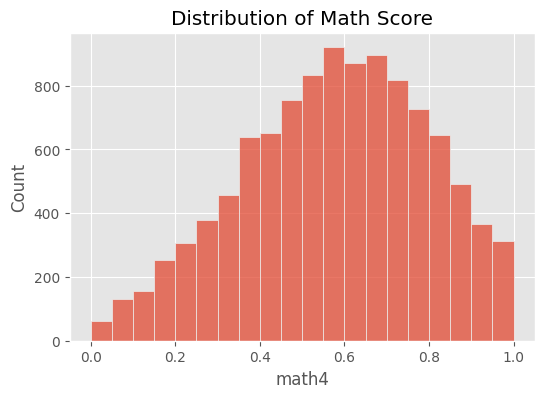

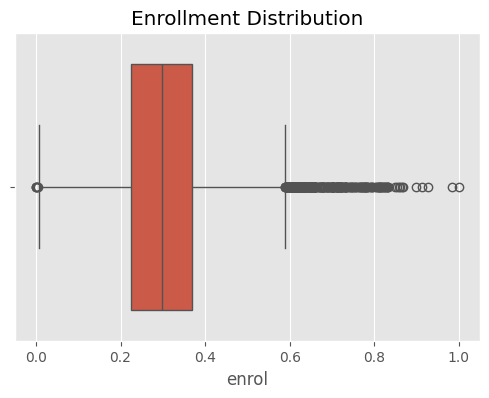

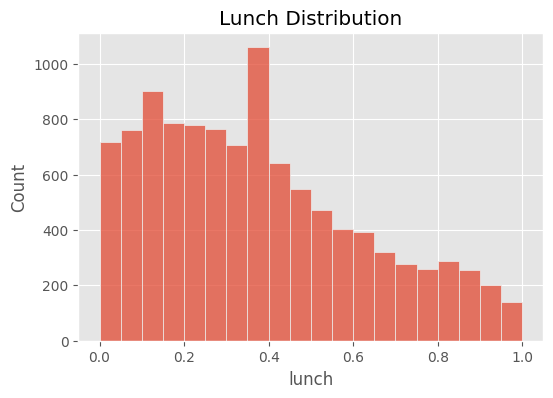

In [8]:
#Univariate Analysis
plt.figure(figsize=(6,4))
sns.histplot(df["math4"], bins=20)
plt.title("Distribution of Math Score")
plt.show()

plt.figure(figsize=(6,4))
sns.boxplot(x=df["enrol"])
plt.title("Enrollment Distribution")
plt.show()

plt.figure(figsize=(6,4))
sns.histplot(df["lunch"], bins=20)
plt.title("Lunch Distribution")
plt.show()

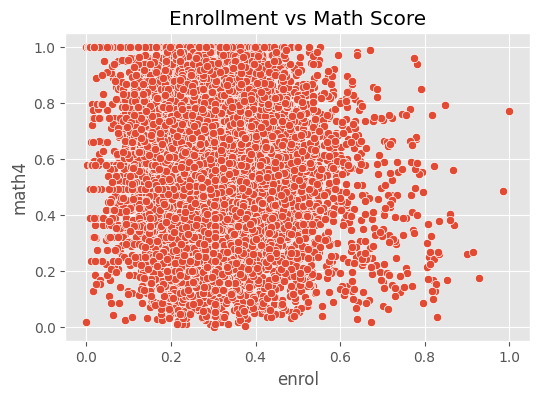

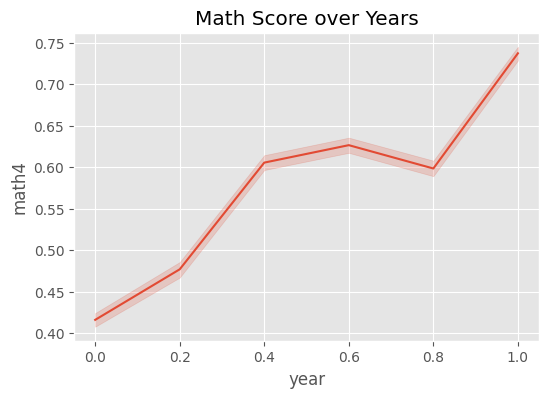

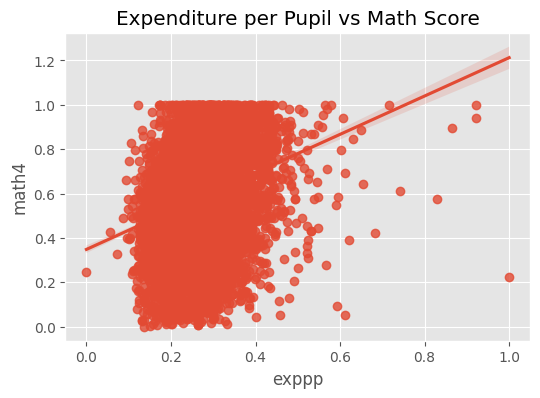

In [9]:
#Bivariate Analysis
plt.figure(figsize=(6,4))
sns.scatterplot(x="enrol", y="math4", data=df)
plt.title("Enrollment vs Math Score")
plt.show()

plt.figure(figsize=(6,4))
sns.lineplot(x="year", y="math4", data=df)
plt.title("Math Score over Years")
plt.show()

plt.figure(figsize=(6,4))
sns.regplot(x="exppp", y="math4", data=df)
plt.title("Expenditure per Pupil vs Math Score")
plt.show()

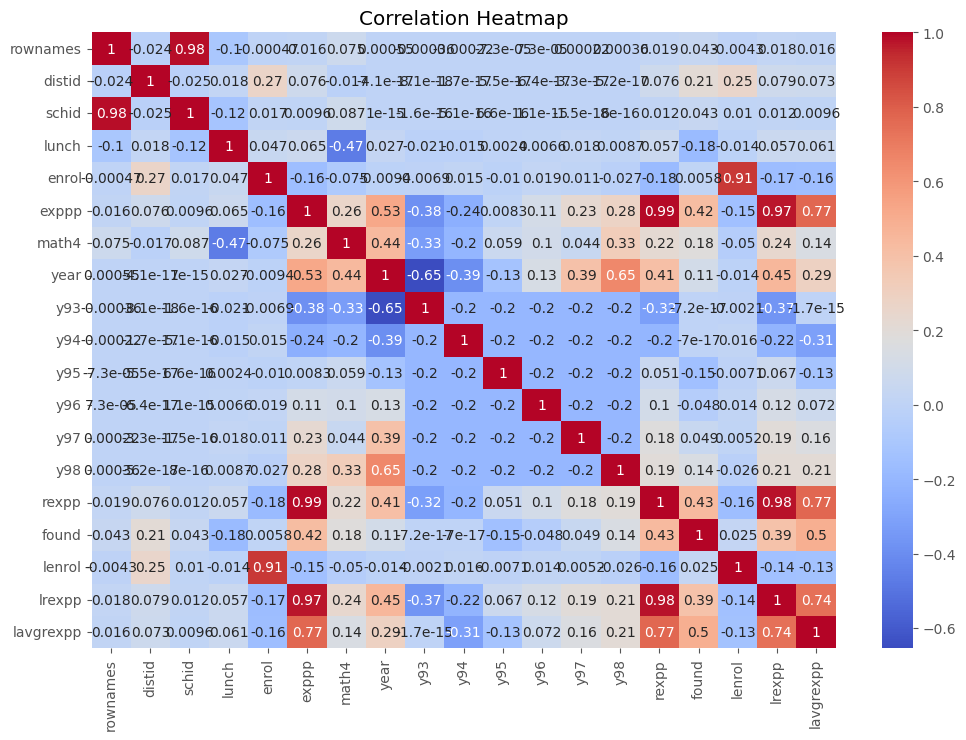

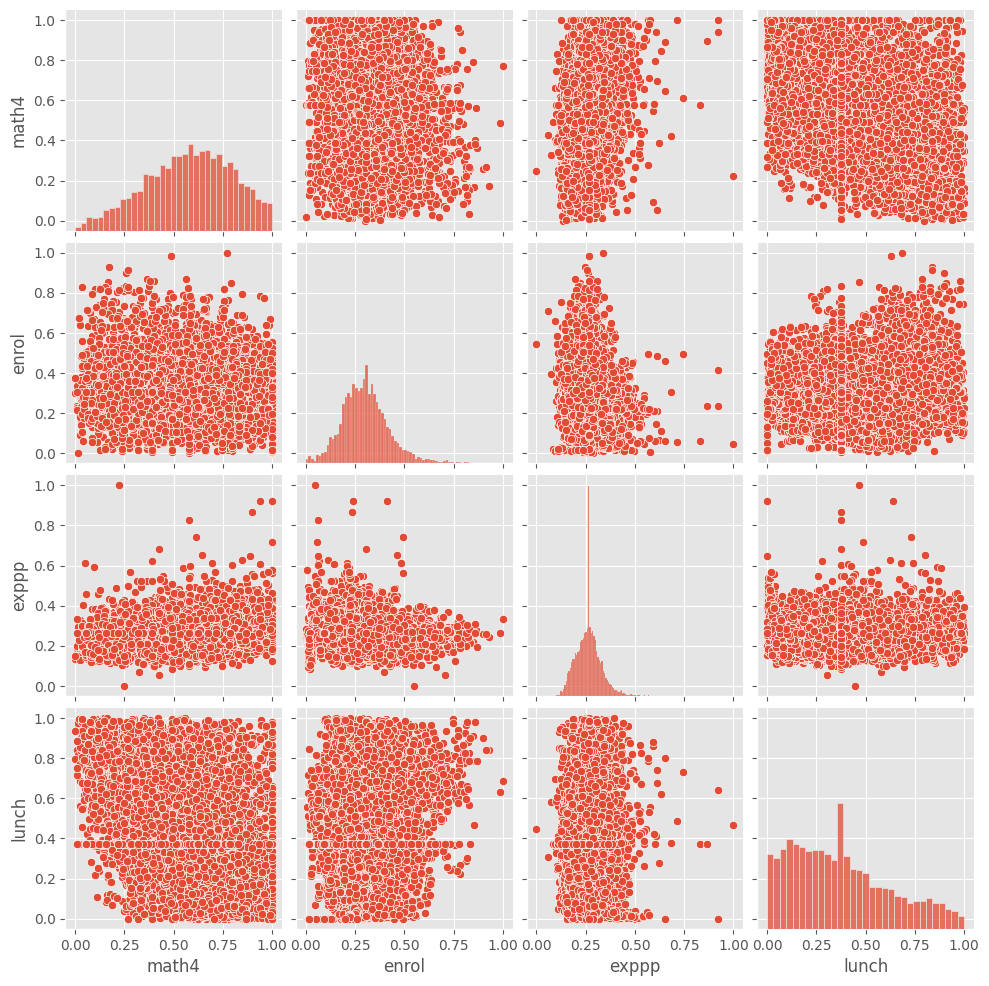

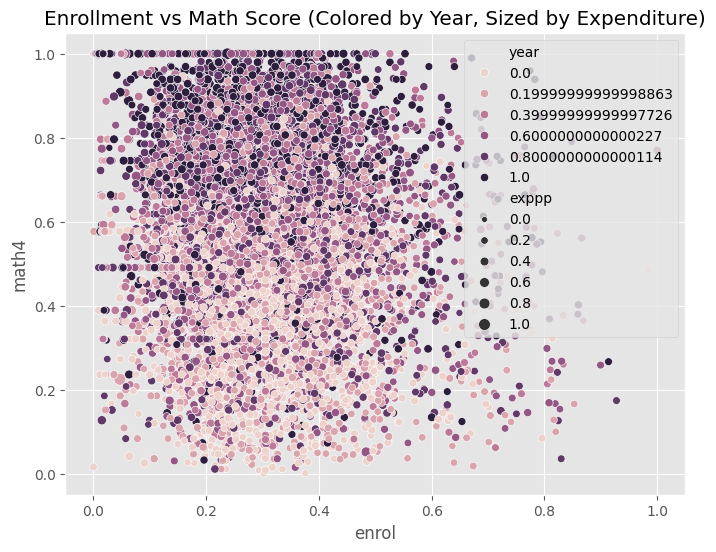

In [10]:
#Multivariate Analysis

plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


sns.pairplot(df[['math4', 'enrol', 'exppp', 'lunch']])
plt.show()


plt.figure(figsize=(8,6))
sns.scatterplot(x='enrol', y='math4', hue='year', size='exppp', data=df)
plt.title("Enrollment vs Math Score (Colored by Year, Sized by Expenditure)")
plt.show()

1D STATISTICAL ANALYSIS

Descriptive Statistical Analysis:


,Mean,Median,Mode,Variance,Standard Deviation,Minimum,Q1,Median (Q2),Q3,IQR,Maximum,Skewness,Kurtosis
lunch,0.374,0.344,0.374,0.062,0.250,0.0,0.169,0.344,0.533,0.364,1.0,0.575,-0.537
enrol,0.305,0.297,0.305,0.015,0.123,0.0,0.224,0.297,0.370,0.146,1.0,0.776,1.800
exppp,0.264,0.264,0.264,0.004,0.066,0.0,0.223,0.264,0.297,0.074,1.0,1.141,6.302
math4,0.577,0.587,0.491,0.048,0.219,0.0,0.423,0.587,0.742,0.320,1.0,-0.249,-0.576
rexpp,0.251,0.251,0.251,0.003,0.058,0.0,0.215,0.251,0.278,0.063,1.0,1.426,8.770
found,0.243,0.243,0.243,0.016,0.128,0.0,0.182,0.243,0.243,0.060,1.0,2.224,8.281
lenrol,0.759,0.769,0.759,0.008,0.091,0.0,0.719,0.769,0.813,0.093,1.0,-1.833,8.100
lrexpp,0.658,0.658,0.658,0.003,0.053,0.0,0.628,0.658,0.688,0.060,1.0,-0.119,3.627
lavgrexpp,0.431,0.431,0.431,0.006,0.081,0.0,0.396,0.431,0.463,0.067,1.0,0.255,2.494


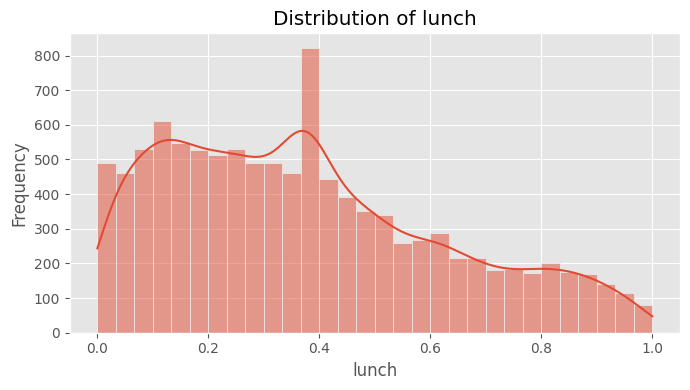

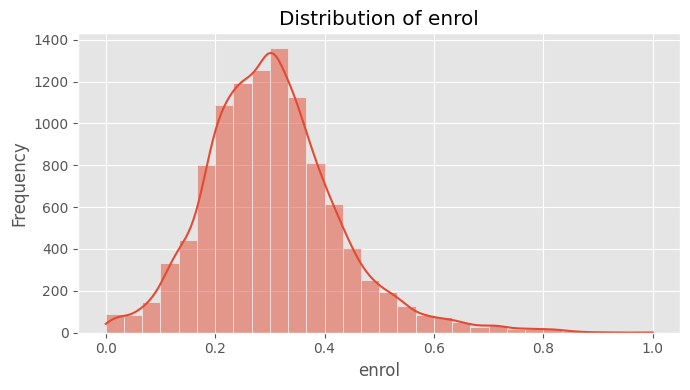

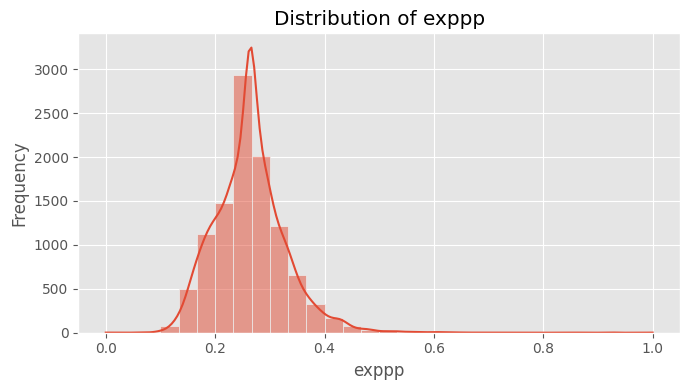

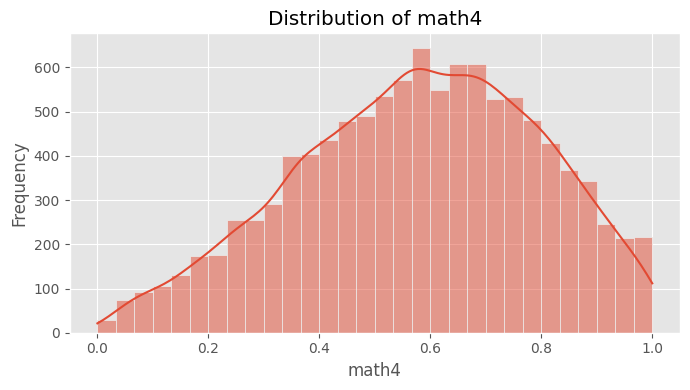

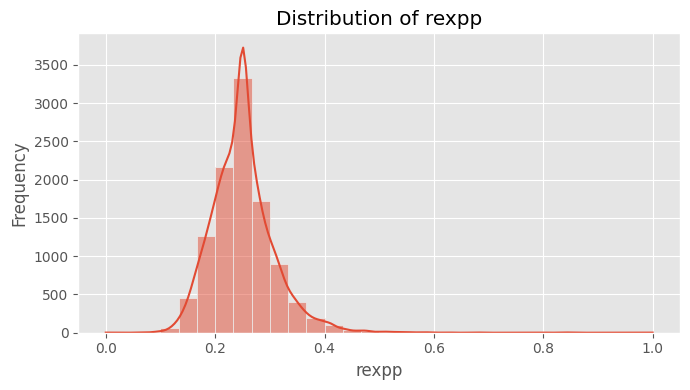

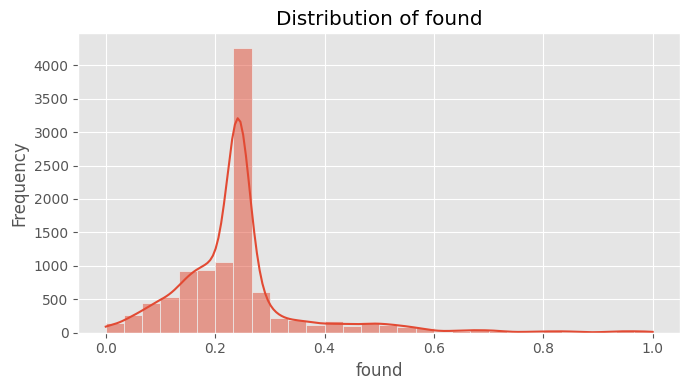

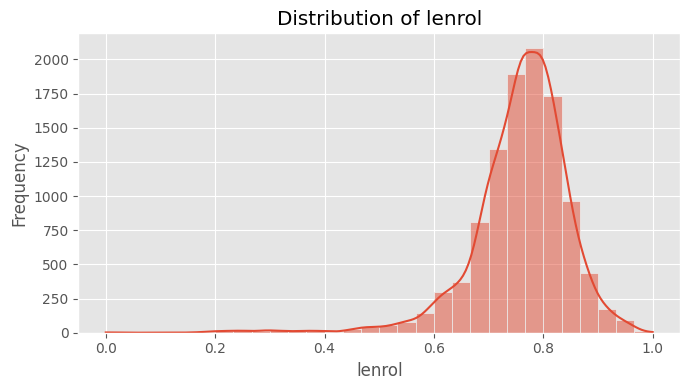

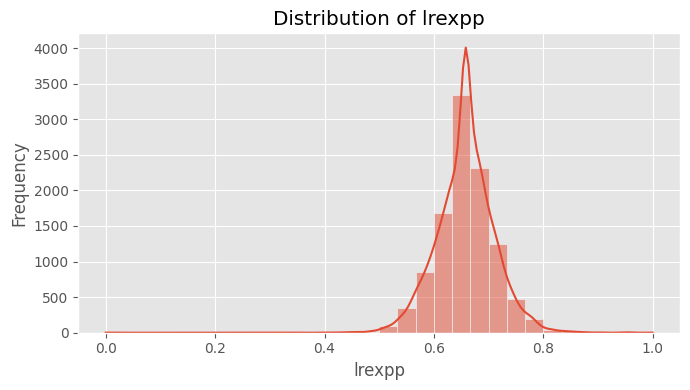

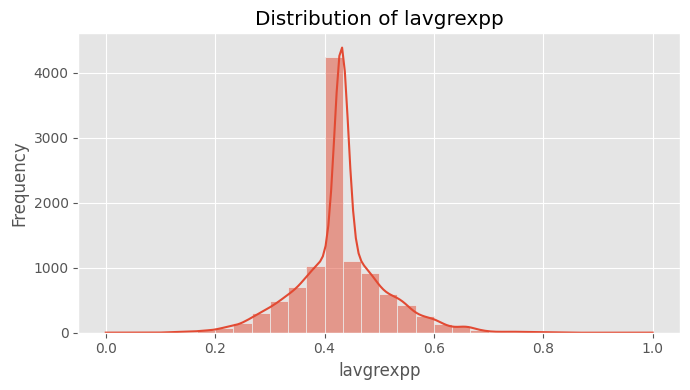

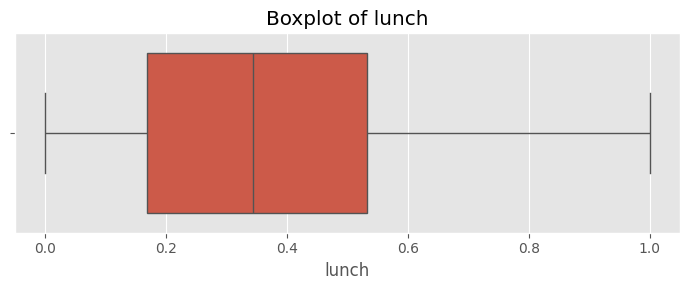

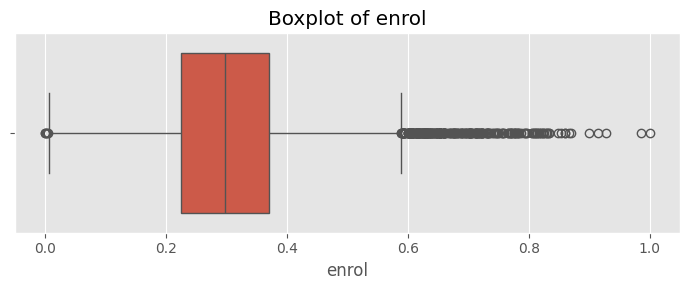

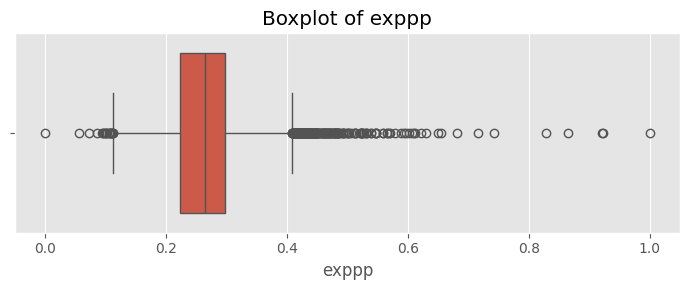

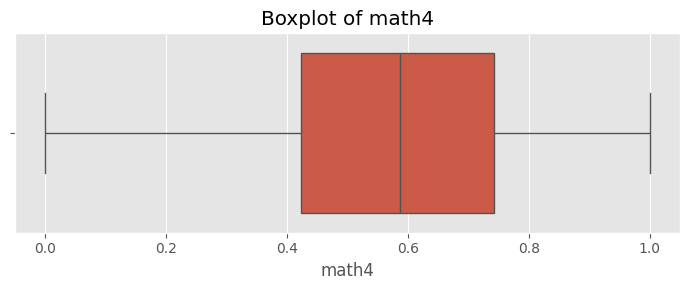

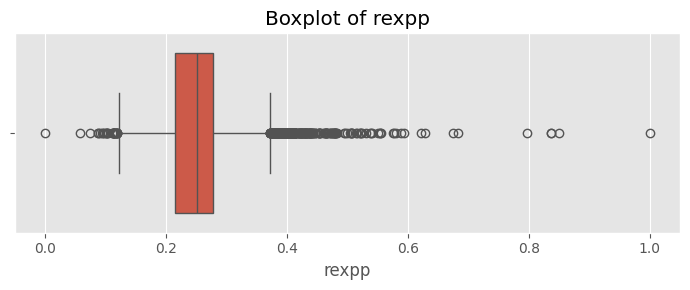

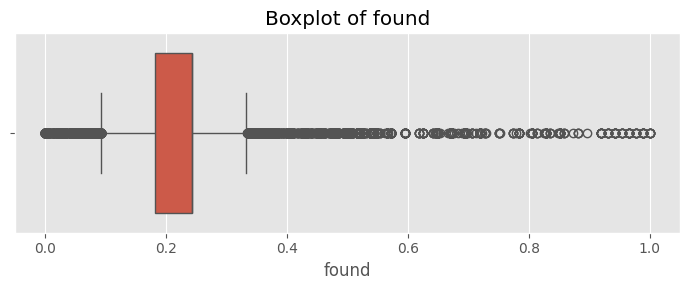

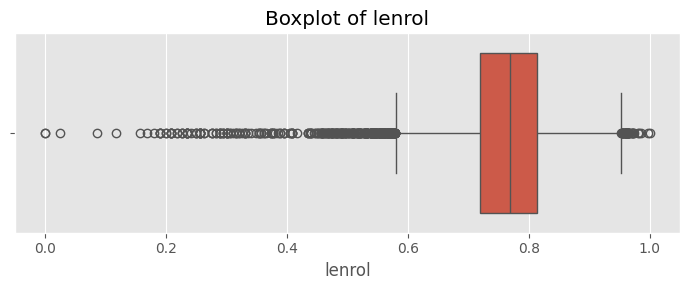

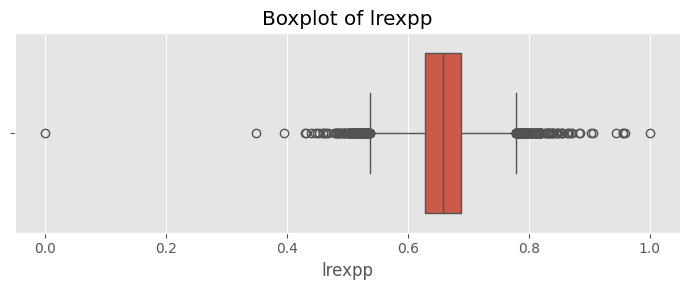

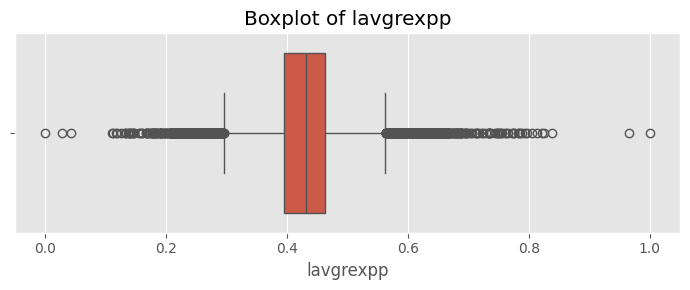


Distribution Interpretation:
lunch: Positively Skewed (Skewness = 0.575)
enrol: Positively Skewed (Skewness = 0.776)
exppp: Positively Skewed (Skewness = 1.141)
math4: Approximately Symmetric (Skewness = -0.249)
rexpp: Positively Skewed (Skewness = 1.426)
found: Positively Skewed (Skewness = 2.224)
lenrol: Negatively Skewed (Skewness = -1.833)
lrexpp: Approximately Symmetric (Skewness = -0.119)
lavgrexpp: Approximately Symmetric (Skewness = 0.255)


In [11]:

#  1D STATISTICAL ANALYSIS

# Variables selected for 1D statistical analysis
one_d_cols = ['lunch', 'enrol', 'exppp', 'math4',
              'rexpp', 'found', 'lenrol', 'lrexpp', 'lavgrexpp']

one_d = df[one_d_cols].copy()

print("=" * 70)
print("1D STATISTICAL ANALYSIS")
print("=" * 70)

# Descriptive statistics
summary_1d = pd.DataFrame({
    'Mean': one_d.mean(),
    'Median': one_d.median(),
    'Mode': one_d.mode().iloc[0],
    'Variance': one_d.var(),
    'Standard Deviation': one_d.std(),
    'Minimum': one_d.min(),
    'Q1': one_d.quantile(0.25),
    'Median (Q2)': one_d.quantile(0.50),
    'Q3': one_d.quantile(0.75),
    'IQR': one_d.quantile(0.75) - one_d.quantile(0.25),
    'Maximum': one_d.max(),
    'Skewness': one_d.skew(),
    'Kurtosis': one_d.kurtosis()
})

print("\nDescriptive Statistical Analysis:")
display(summary_1d.round(3))

# Histograms
for column in one_d_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(one_d[column], bins=30, kde=True)
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

# Boxplots
for column in one_d_cols:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=one_d[column])
    plt.title(f'Boxplot of {column}')
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()

print("\nDistribution Interpretation:")
for column in one_d_cols:
    skewness = one_d[column].skew()

    if skewness > 0.5:
        result = "Positively Skewed"
    elif skewness < -0.5:
        result = "Negatively Skewed"
    else:
        result = "Approximately Symmetric"

    print(
        f"{column}: {result} "
        f"(Skewness = {skewness:.3f})"
    )

2D STATISTICAL ANALYSIS

COVARIANCE MATRIX


,lunch,enrol,exppp,math4,rexpp,found,lenrol,lrexpp,lavgrexpp
lunch,0.062,0.001,0.001,-0.026,0.001,-0.006,-0.000,0.001,0.001
enrol,0.001,0.015,-0.001,-0.002,-0.001,0.000,0.010,-0.001,-0.002
exppp,0.001,-0.001,0.004,0.004,0.004,0.004,-0.001,0.003,0.004
math4,-0.026,-0.002,0.004,0.048,0.003,0.005,-0.001,0.003,0.003
rexpp,0.001,-0.001,0.004,0.003,0.003,0.003,-0.001,0.003,0.004
found,-0.006,0.000,0.004,0.005,0.003,0.016,0.000,0.003,0.005
lenrol,-0.000,0.010,-0.001,-0.001,-0.001,0.000,0.008,-0.001,-0.001
lrexpp,0.001,-0.001,0.003,0.003,0.003,0.003,-0.001,0.003,0.003
lavgrexpp,0.001,-0.002,0.004,0.003,0.004,0.005,-0.001,0.003,0.006



PEARSON CORRELATION MATRIX


,lunch,enrol,exppp,math4,rexpp,found,lenrol,lrexpp,lavgrexpp
lunch,1.000,0.047,0.065,-0.468,0.057,-0.179,-0.014,0.057,0.061
enrol,0.047,1.000,-0.163,-0.075,-0.178,0.006,0.906,-0.167,-0.159
exppp,0.065,-0.163,1.000,0.261,0.989,0.423,-0.150,0.972,0.768
math4,-0.468,-0.075,0.261,1.000,0.220,0.183,-0.050,0.242,0.142
rexpp,0.057,-0.178,0.989,0.220,1.000,0.431,-0.162,0.976,0.770
found,-0.179,0.006,0.423,0.183,0.431,1.000,0.025,0.387,0.496
lenrol,-0.014,0.906,-0.150,-0.050,-0.162,0.025,1.000,-0.142,-0.134
lrexpp,0.057,-0.167,0.972,0.242,0.976,0.387,-0.142,1.000,0.740
lavgrexpp,0.061,-0.159,0.768,0.142,0.770,0.496,-0.134,0.740,1.000



SPEARMAN CORRELATION MATRIX


,lunch,enrol,exppp,math4,rexpp,found,lenrol,lrexpp,lavgrexpp
lunch,1.000,-0.062,0.052,-0.459,0.048,-0.132,-0.064,0.044,0.048
enrol,-0.062,1.000,-0.165,-0.035,-0.182,0.070,0.999,-0.181,-0.167
exppp,0.052,-0.165,1.000,0.275,0.984,0.255,-0.166,0.984,0.738
math4,-0.459,-0.035,0.275,1.000,0.233,0.059,-0.032,0.244,0.125
rexpp,0.048,-0.182,0.984,0.233,1.000,0.268,-0.183,0.997,0.745
found,-0.132,0.070,0.255,0.059,0.268,1.000,0.071,0.262,0.410
lenrol,-0.064,0.999,-0.166,-0.032,-0.183,0.071,1.000,-0.181,-0.167
lrexpp,0.044,-0.181,0.984,0.244,0.997,0.262,-0.181,1.000,0.741
lavgrexpp,0.048,-0.167,0.738,0.125,0.745,0.410,-0.167,0.741,1.000


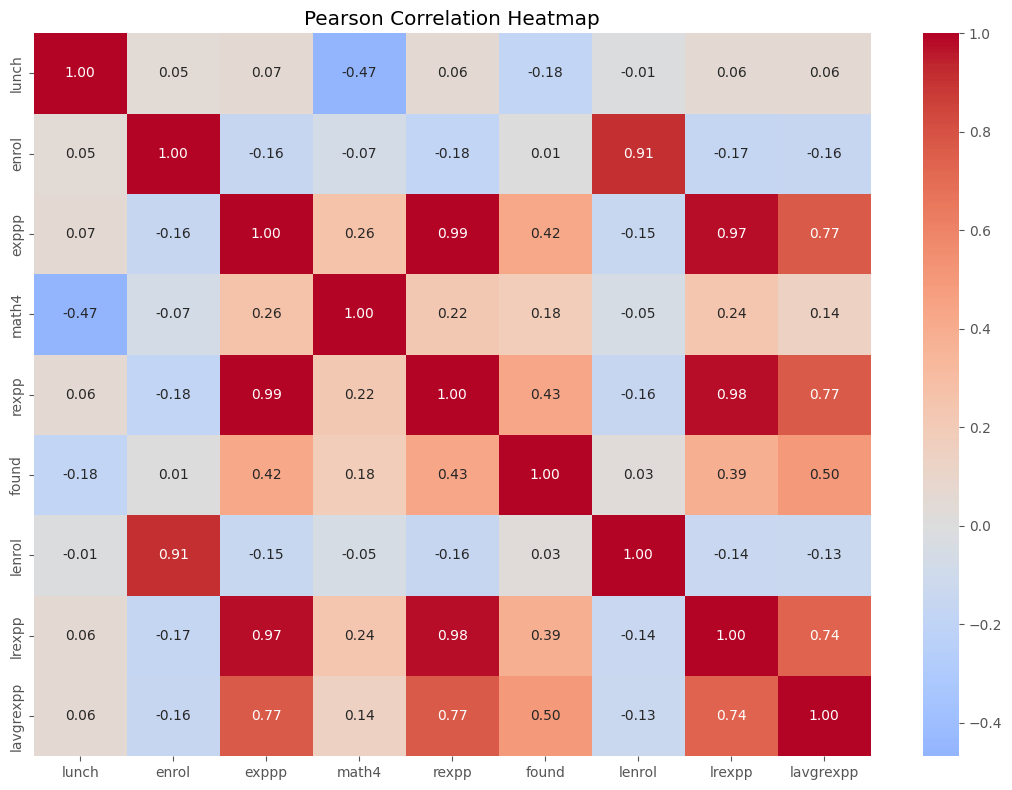


PAIRWISE STATISTICAL ANALYSIS

--------------------------------------------------
enrol vs math4
Pearson Correlation = -0.0747
P-value = 0.000000
Result: Statistically significant relationship


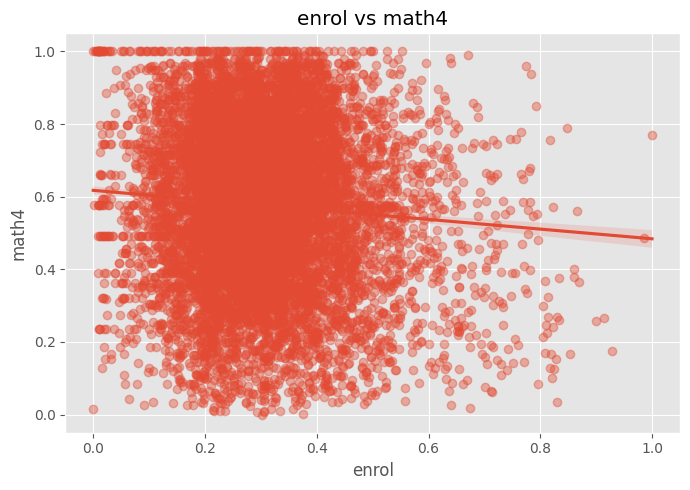


--------------------------------------------------
exppp vs math4
Pearson Correlation = 0.2607
P-value = 0.000000
Result: Statistically significant relationship


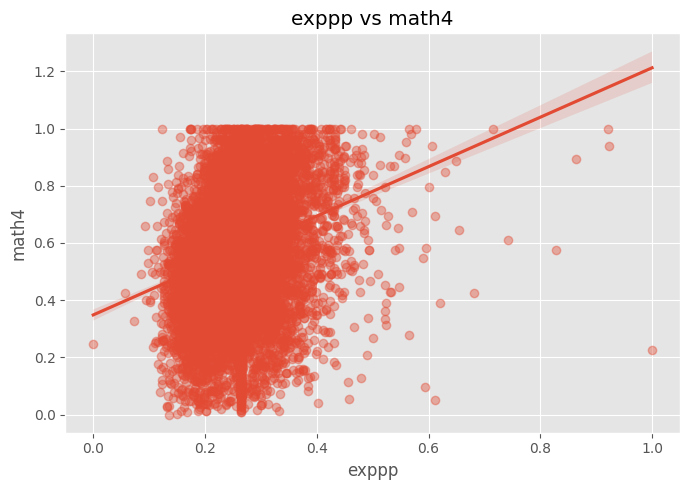


--------------------------------------------------
lunch vs math4
Pearson Correlation = -0.4681
P-value = 0.000000
Result: Statistically significant relationship


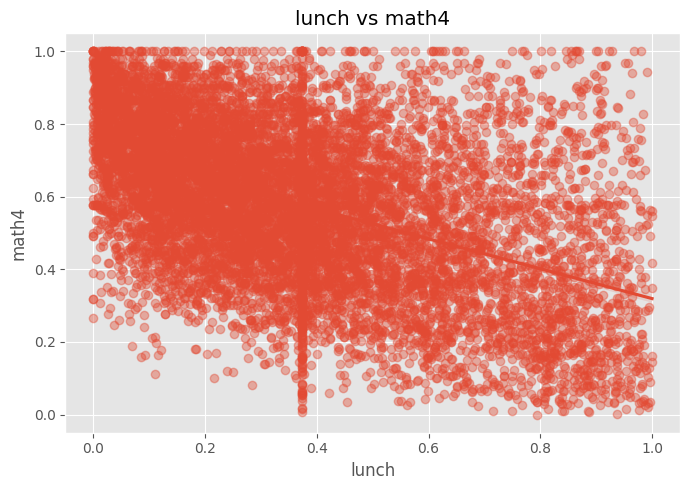


--------------------------------------------------
enrol vs exppp
Pearson Correlation = -0.1627
P-value = 0.000000
Result: Statistically significant relationship


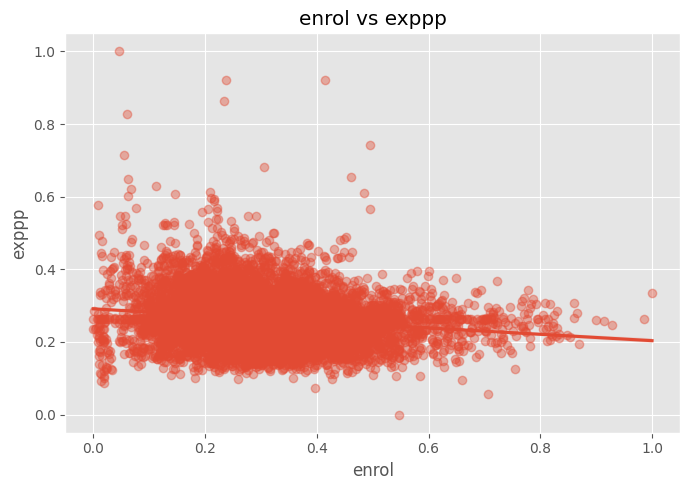


--------------------------------------------------
rexpp vs math4
Pearson Correlation = 0.2204
P-value = 0.000000
Result: Statistically significant relationship


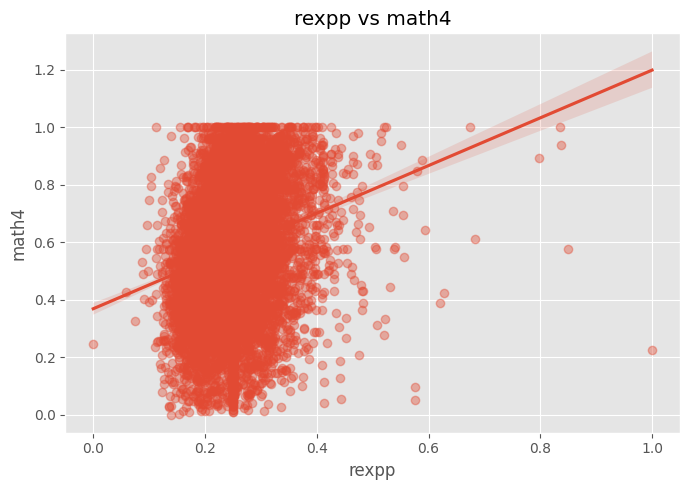

In [12]:

from scipy import stats

two_d_cols = [
    'lunch',
    'enrol',
    'exppp',
    'math4',
    'rexpp',
    'found',
    'lenrol',
    'lrexpp',
    'lavgrexpp'
]

two_d = df[two_d_cols].copy()

print("=" * 70)
print("2D STATISTICAL ANALYSIS")
print("=" * 70)

# Covariance
print("\nCOVARIANCE MATRIX")
covariance = two_d.cov()
display(covariance.round(3))

# Pearson correlation
print("\nPEARSON CORRELATION MATRIX")
pearson = two_d.corr(method='pearson')
display(pearson.round(3))

# Spearman correlation
print("\nSPEARMAN CORRELATION MATRIX")
spearman = two_d.corr(method='spearman')
display(spearman.round(3))

# Pearson correlation heatmap
plt.figure(figsize=(11, 8))
sns.heatmap(
    pearson,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)
plt.title('Pearson Correlation Heatmap')
plt.tight_layout()
plt.show()

# Important pairwise relationships
pairs = [
    ('enrol', 'math4'),
    ('exppp', 'math4'),
    ('lunch', 'math4'),
    ('enrol', 'exppp'),
    ('rexpp', 'math4')
]

print("\nPAIRWISE STATISTICAL ANALYSIS")

for x, y in pairs:

    temp = df[[x, y]].dropna()

    r, p_value = stats.pearsonr(
        temp[x],
        temp[y]
    )

    print("\n" + "-" * 50)
    print(f"{x} vs {y}")
    print(f"Pearson Correlation = {r:.4f}")
    print(f"P-value = {p_value:.6f}")

    if p_value < 0.05:
        print("Result: Statistically significant relationship")
    else:
        print("Result: Not statistically significant")

    # Scatter + regression line
    plt.figure(figsize=(7, 5))

    sns.regplot(
        data=temp,
        x=x,
        y=y,
        scatter_kws={'alpha': 0.4}
    )

    plt.title(f'{x} vs {y}')
    plt.xlabel(x)
    plt.ylabel(y)
    plt.tight_layout()
    plt.show()

3D STATISTICAL ANALYSIS

Variables used:
['exppp', 'enrol', 'math4']

Descriptive Statistics:


,exppp,enrol,math4
count,10668.000,10668.000,10668.000
mean,0.264,0.305,0.577
std,0.066,0.123,0.219
min,0.000,0.000,0.000
25%,0.223,0.224,0.423
50%,0.264,0.297,0.587
75%,0.297,0.370,0.742
max,1.000,1.000,1.000



Correlation Matrix:


,exppp,enrol,math4
exppp,1.000,-0.163,0.261
enrol,-0.163,1.000,-0.075
math4,0.261,-0.075,1.000


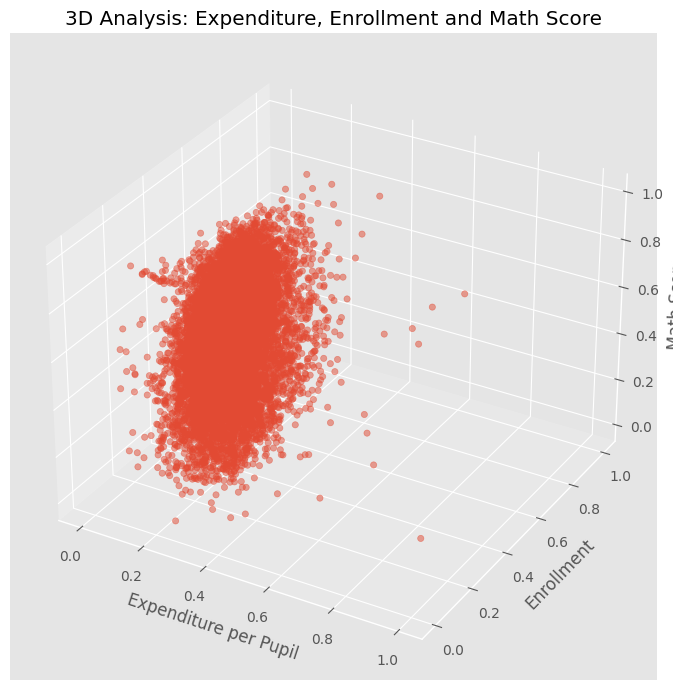


Interpretation:
The 3D analysis examines the combined relationship among expenditure per pupil, enrollment and mathematics score.


In [13]:

# 3D STATISTICAL ANALYSIS


from mpl_toolkits.mplot3d import Axes3D

three_d_cols = [
    'exppp',
    'enrol',
    'math4'
]

three_d = df[three_d_cols].dropna()

print("=" * 70)
print("3D STATISTICAL ANALYSIS")
print("=" * 70)

print("\nVariables used:")
print(three_d_cols)

print("\nDescriptive Statistics:")
display(three_d.describe().round(3))

print("\nCorrelation Matrix:")
display(three_d.corr().round(3))

# 3D Scatter Plot
fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(
    111,
    projection='3d'
)

ax.scatter(
    three_d['exppp'],
    three_d['enrol'],
    three_d['math4'],
    alpha=0.5
)

ax.set_xlabel('Expenditure per Pupil')
ax.set_ylabel('Enrollment')
ax.set_zlabel('Math Score')

ax.set_title(
    '3D Analysis: Expenditure, Enrollment and Math Score'
)

plt.tight_layout()
plt.show()

print("\nInterpretation:")
print(
    "The 3D analysis examines the combined relationship among "
    "expenditure per pupil, enrollment and mathematics score."
)

K-MEANS CLUSTERING

Features used:
['lunch', 'enrol', 'exppp', 'math4', 'rexpp']


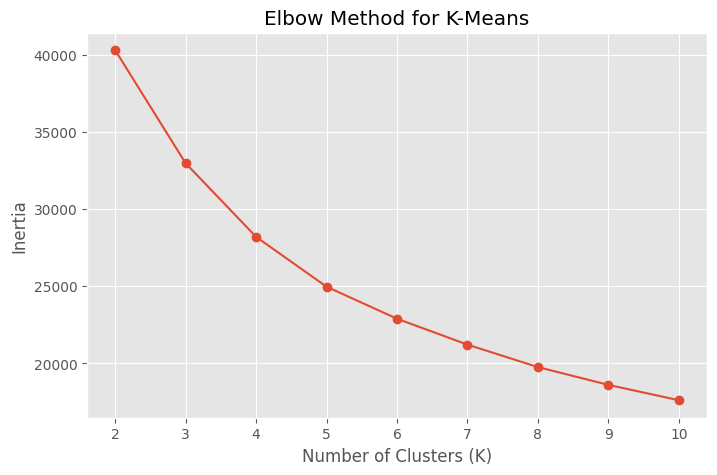


Silhouette Scores:
K = 2: Silhouette Score = 0.2226
K = 3: Silhouette Score = 0.2293
K = 4: Silhouette Score = 0.2258
K = 5: Silhouette Score = 0.2335
K = 6: Silhouette Score = 0.2063
K = 7: Silhouette Score = 0.1939
K = 8: Silhouette Score = 0.2025
K = 9: Silhouette Score = 0.2030
K = 10: Silhouette Score = 0.1982

Selected K = 5

Cluster Sizes:
Cluster
0    1086
1    2407
2    1074
3    2244
4    3857
Name: count, dtype: int64

Cluster Profiles:


,lunch,enrol,exppp,math4,rexpp
Cluster,,,,,
0,0.329,0.233,0.388,0.719,0.362
1,0.311,0.302,0.188,0.478,0.187
2,0.658,0.523,0.258,0.441,0.244
3,0.608,0.240,0.280,0.410,0.265
4,0.210,0.304,0.270,0.733,0.253


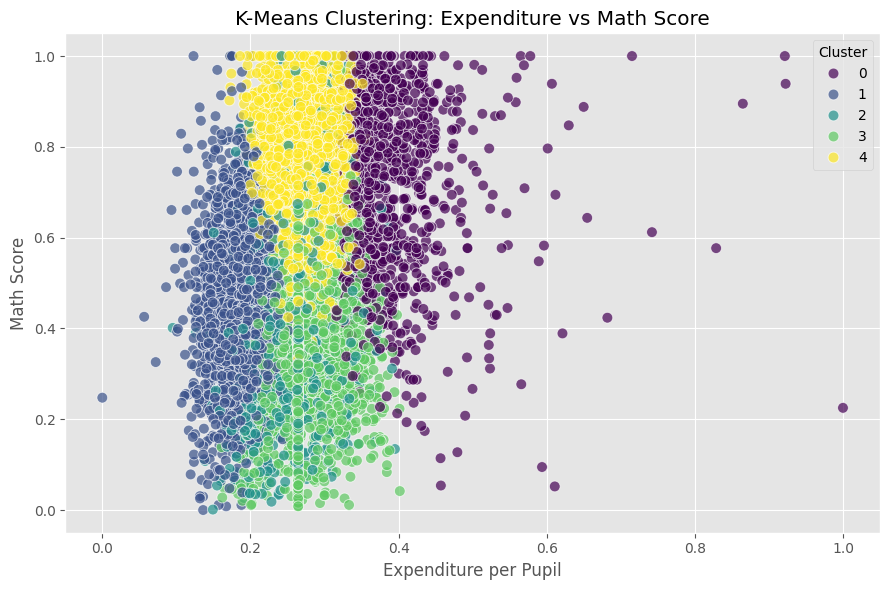

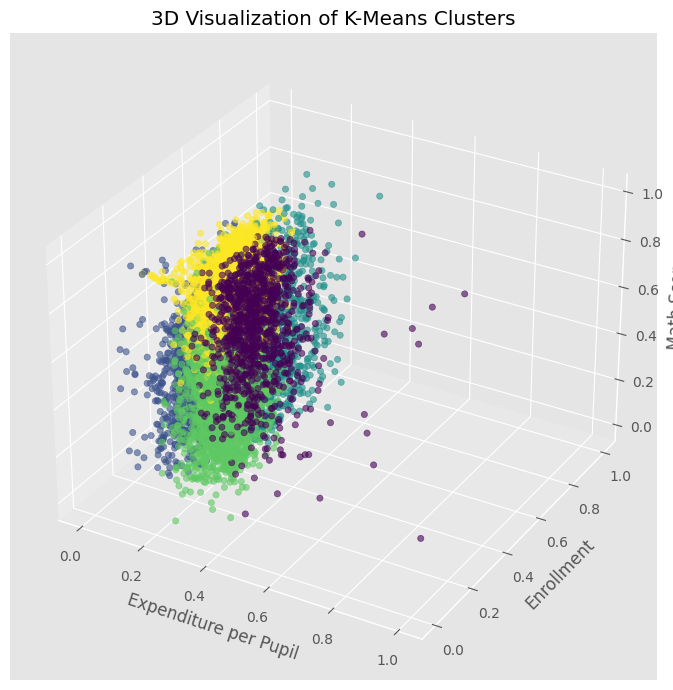

In [14]:

# K-MEANS CLUSTERING

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_features = [
    'lunch',
    'enrol',
    'exppp',
    'math4',
    'rexpp'
]

cluster_data = df[cluster_features].dropna().copy()

print("=" * 70)
print("K-MEANS CLUSTERING")
print("=" * 70)

print("\nFeatures used:")
print(cluster_features)

# Standardization
scaler_kmeans = StandardScaler()

X = scaler_kmeans.fit_transform(
    cluster_data
)

# Elbow Method
inertia = []

K_values = range(2, 11)

for k in K_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X)

    inertia.append(
        model.inertia_
    )

plt.figure(figsize=(8, 5))

plt.plot(
    K_values,
    inertia,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for K-Means')
plt.xticks(K_values)
plt.grid(True)
plt.show()

# Silhouette scores
silhouette_scores = {}

for k in K_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    silhouette_scores[k] = silhouette_score(
        X,
        labels
    )

print("\nSilhouette Scores:")

for k, score in silhouette_scores.items():
    print(
        f"K = {k}: "
        f"Silhouette Score = {score:.4f}"
    )

# Select K using highest silhouette score
best_k = max(
    silhouette_scores,
    key=silhouette_scores.get
)

print(f"\nSelected K = {best_k}")

# Final K-Means
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_data['Cluster'] = kmeans.fit_predict(X)

print("\nCluster Sizes:")
print(
    cluster_data['Cluster']
    .value_counts()
    .sort_index()
)

print("\nCluster Profiles:")
display(
    cluster_data
    .groupby('Cluster')[cluster_features]
    .mean()
    .round(3)
)

# 2D visualization
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=cluster_data,
    x='exppp',
    y='math4',
    hue='Cluster',
    palette='viridis',
    s=60,
    alpha=0.7
)

plt.title(
    'K-Means Clustering: Expenditure vs Math Score'
)

plt.xlabel('Expenditure per Pupil')
plt.ylabel('Math Score')

plt.tight_layout()
plt.show()

# 3D visualization
fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(
    111,
    projection='3d'
)

ax.scatter(
    cluster_data['exppp'],
    cluster_data['enrol'],
    cluster_data['math4'],
    c=cluster_data['Cluster'],
    cmap='viridis',
    alpha=0.6
)

ax.set_xlabel('Expenditure per Pupil')
ax.set_ylabel('Enrollment')
ax.set_zlabel('Math Score')

ax.set_title(
    '3D Visualization of K-Means Clusters'
)

plt.tight_layout()
plt.show()

HIERARCHICAL CLUSTERING


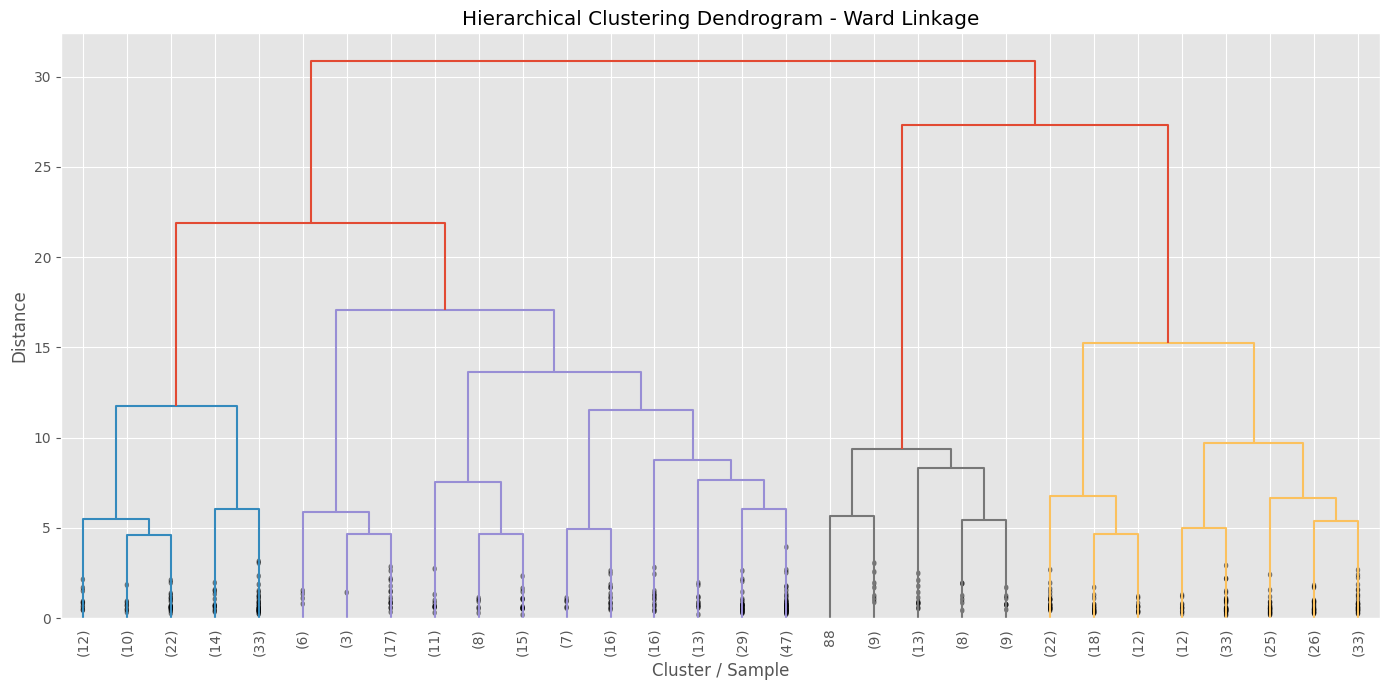


Number of clusters: 5

Cluster Sizes:
Cluster
0    181
1    162
2     40
3     91
4     26
Name: count, dtype: int64

Cluster Profiles:


,lunch,enrol,exppp,math4,rexpp
Cluster,,,,,
0,0.174,0.301,0.279,0.741,0.262
1,0.554,0.281,0.266,0.450,0.252
2,0.546,0.215,0.407,0.543,0.380
3,0.319,0.283,0.187,0.494,0.187
4,0.727,0.579,0.273,0.529,0.255



Silhouette Score = 0.2087


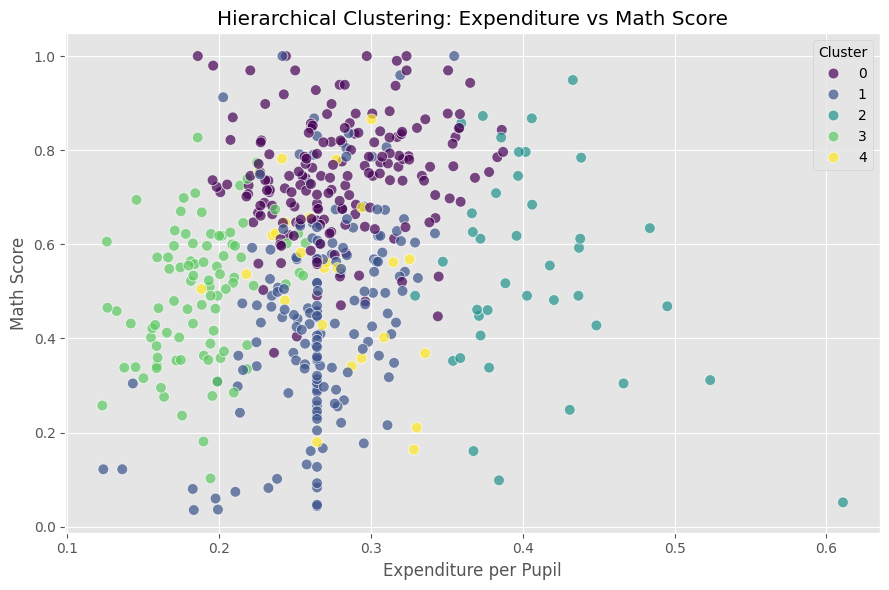

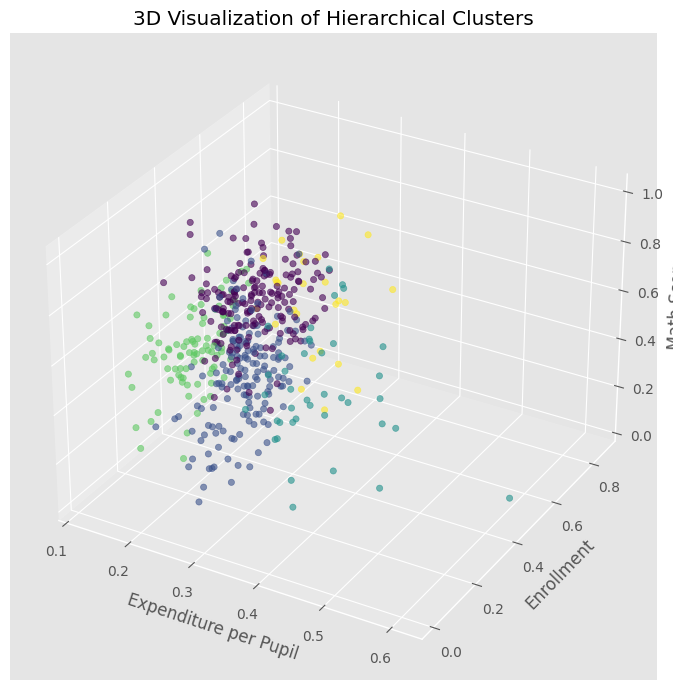

In [15]:

#  HIERARCHICAL CLUSTERING


from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

hier_features = [
    'lunch',
    'enrol',
    'exppp',
    'math4',
    'rexpp'
]

hier_data = df[hier_features].dropna().copy()

print("=" * 70)
print("HIERARCHICAL CLUSTERING")
print("=" * 70)

# Standardization
scaler_hier = StandardScaler()

X_hier = scaler_hier.fit_transform(
    hier_data
)

# Use a sample for a readable dendrogram
sample_size = min(500, len(X_hier))

np.random.seed(42)

sample_indices = np.random.choice(
    len(X_hier),
    size=sample_size,
    replace=False
)

X_sample = X_hier[sample_indices]

# Ward linkage
linkage_matrix = linkage(
    X_sample,
    method='ward'
)

# Dendrogram
plt.figure(figsize=(14, 7))

dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True
)

plt.title(
    'Hierarchical Clustering Dendrogram - Ward Linkage'
)

plt.xlabel('Cluster / Sample')
plt.ylabel('Distance')

plt.tight_layout()
plt.show()

# Use the K selected by K-Means
n_clusters = best_k

hierarchical_model = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage='ward'
)

hierarchical_labels = (
    hierarchical_model.fit_predict(X_sample)
)

# Create sample dataframe
hier_sample = hier_data.iloc[
    sample_indices
].copy()

hier_sample['Cluster'] = hierarchical_labels

print(f"\nNumber of clusters: {n_clusters}")

print("\nCluster Sizes:")
print(
    hier_sample['Cluster']
    .value_counts()
    .sort_index()
)

print("\nCluster Profiles:")
display(
    hier_sample
    .groupby('Cluster')[hier_features]
    .mean()
    .round(3)
)

# Silhouette score
hier_silhouette = silhouette_score(
    X_sample,
    hierarchical_labels
)

print(
    f"\nSilhouette Score = "
    f"{hier_silhouette:.4f}"
)

# 2D visualization
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=hier_sample,
    x='exppp',
    y='math4',
    hue='Cluster',
    palette='viridis',
    s=60,
    alpha=0.7
)

plt.title(
    'Hierarchical Clustering: Expenditure vs Math Score'
)

plt.xlabel('Expenditure per Pupil')
plt.ylabel('Math Score')

plt.tight_layout()
plt.show()

# 3D visualization
fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(
    111,
    projection='3d'
)

ax.scatter(
    hier_sample['exppp'],
    hier_sample['enrol'],
    hier_sample['math4'],
    c=hier_sample['Cluster'],
    cmap='viridis',
    alpha=0.6
)

ax.set_xlabel('Expenditure per Pupil')
ax.set_ylabel('Enrollment')
ax.set_zlabel('Math Score')

ax.set_title(
    '3D Visualization of Hierarchical Clusters'
)

plt.tight_layout()
plt.show()

In [16]:
# PRINCIPAL COMPONENT ANALYSIS (PCA)

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

# Load original dataset
pca_df = pd.read_csv(url)

# Select numerical features
pca_features = [
    'lunch', 'enrol', 'exppp', 'math4',
    'rexpp', 'found', 'lenrol', 'lrexpp', 'lavgrexpp'
]

pca_data = pca_df[pca_features].apply(
    pd.to_numeric, errors='coerce'
)

# Handle missing values
imputer = SimpleImputer(strategy='median')
pca_imputed = imputer.fit_transform(pca_data)

# Standardize the data
scaler = StandardScaler()
pca_scaled = scaler.fit_transform(pca_imputed)

# Apply PCA
pca_model = PCA()
pca_result = pca_model.fit_transform(pca_scaled)

print("Original Number of Features:", len(pca_features))
print("Number of Principal Components:", pca_model.n_components_)

Original Number of Features: 9
Number of Principal Components: 9


,Principal Component,Explained Variance,Cumulative Variance
0,PC1,0.4559,0.4559
1,PC2,0.2051,0.6610
2,PC3,0.1652,0.8262
3,PC4,0.0755,0.9017
4,PC5,0.0508,0.9525
5,PC6,0.0329,0.9855
6,PC7,0.0103,0.9957
7,PC8,0.0032,0.9990
8,PC9,0.0010,1.0000


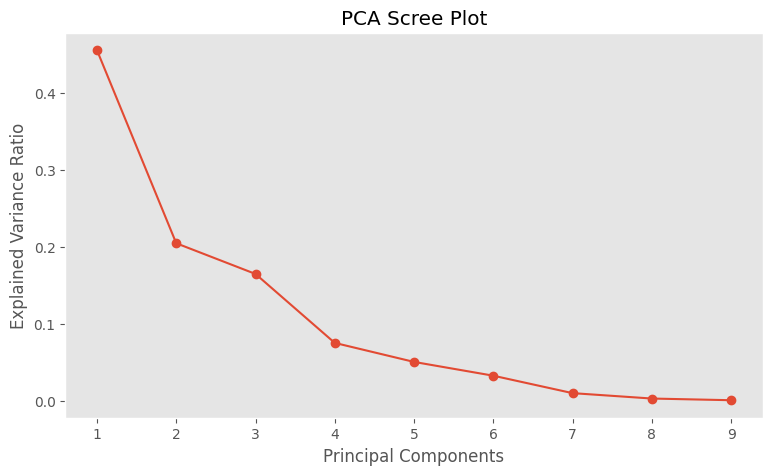

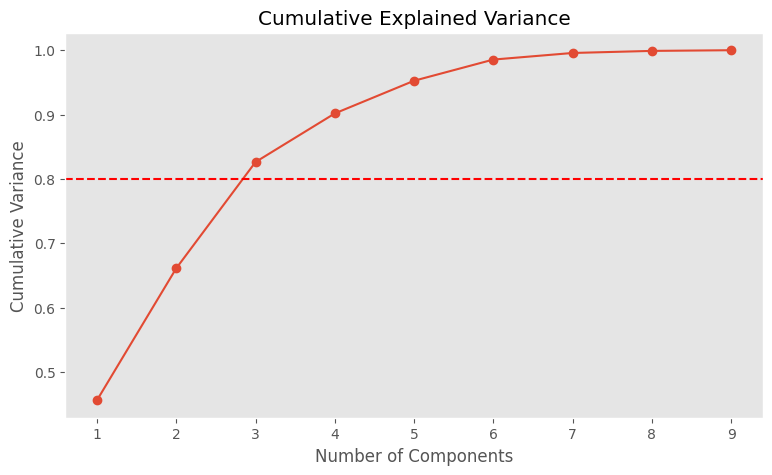

Components required for 80% variance: 3


In [17]:
# EXPLAINED VARIANCE

explained_variance = pca_model.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

variance_df = pd.DataFrame({
    'Principal Component': [
        f'PC{i+1}' for i in range(len(explained_variance))
    ],
    'Explained Variance': explained_variance,
    'Cumulative Variance': cumulative_variance
})

display(variance_df.round(4))

# Scree Plot
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker='o'
)

plt.title('PCA Scree Plot')
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance Ratio')
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid()
plt.show()

# Cumulative Variance
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.axhline(y=0.80, color='red', linestyle='--')

plt.title('Cumulative Explained Variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Variance')
plt.grid()
plt.show()

components_80 = np.argmax(cumulative_variance >= 0.80) + 1

print("Components required for 80% variance:", components_80)

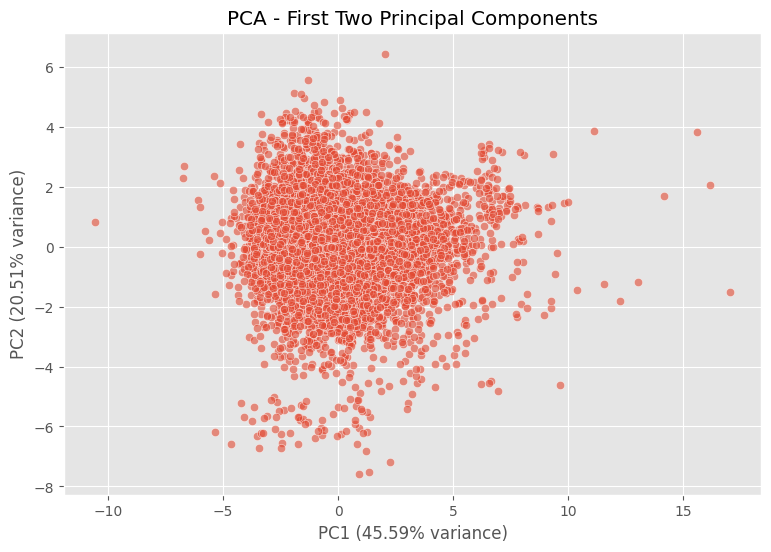

PCA Loadings:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
lunch,-0.007,0.005,0.725,-0.105,0.677,-0.005,-0.057,0.009,0.025
enrol,-0.140,0.685,0.033,-0.086,0.004,0.004,0.705,0.069,0.007
exppp,0.476,0.074,0.082,-0.187,-0.079,-0.187,0.052,-0.495,-0.661
math4,0.160,0.019,-0.632,-0.428,0.610,0.131,-0.014,0.009,0.042
rexpp,0.476,0.063,0.094,-0.161,-0.144,-0.205,0.037,-0.344,0.743
found,0.298,0.185,-0.197,0.804,0.334,-0.280,-0.016,0.034,-0.004
lenrol,-0.129,0.690,-0.004,-0.078,-0.072,0.044,-0.698,-0.077,0.005
lrexpp,0.468,0.070,0.091,-0.226,-0.145,-0.240,-0.081,0.790,-0.092
lavgrexpp,0.420,0.068,0.100,0.185,-0.067,0.876,0.026,0.043,0.000


In [18]:
# PCA 2D VISUALIZATION

pca_2d = pd.DataFrame(
    pca_result[:, :2],
    columns=['PC1', 'PC2']
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_2d,
    x='PC1',
    y='PC2',
    alpha=0.6
)

plt.title('PCA - First Two Principal Components')
plt.xlabel(f"PC1 ({explained_variance[0]*100:.2f}% variance)")
plt.ylabel(f"PC2 ({explained_variance[1]*100:.2f}% variance)")

plt.show()

# Principal Component Loadings
loadings = pd.DataFrame(
    pca_model.components_.T,
    index=pca_features,
    columns=[f'PC{i+1}' for i in range(len(pca_features))]
)

print("PCA Loadings:")
display(loadings.round(3))

In [19]:
# SIMPLE LINEAR REGRESSION

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load original dataset
slr_df = pd.read_csv(url)

# Select variables
slr_data = slr_df[['lunch', 'math4']].copy()

# Convert to numeric
slr_data['lunch'] = pd.to_numeric(
    slr_data['lunch'], errors='coerce'
)

slr_data['math4'] = pd.to_numeric(
    slr_data['math4'], errors='coerce'
)

# Remove missing values
slr_data.dropna(inplace=True)

print("Dataset Shape:", slr_data.shape)

display(slr_data.head())

Dataset Shape: (10275, 2)


,lunch,math4
0,39.799999,46.599998
1,35.000000,44.700001
2,36.590000,86.500000
3,40.549999,84.300003
4,49.490002,83.800003


Correlation Coefficient: -0.4795


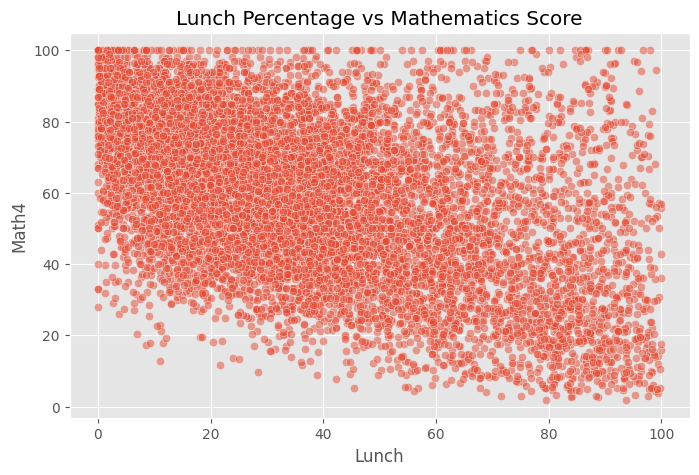

In [20]:
# CORRELATION ANALYSIS

correlation = slr_data['lunch'].corr(slr_data['math4'])

print("Correlation Coefficient:", round(correlation, 4))

# Scatter Plot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=slr_data,
    x='lunch',
    y='math4',
    alpha=0.5
)

plt.title('Lunch Percentage vs Mathematics Score')
plt.xlabel('Lunch')
plt.ylabel('Math4')

plt.show()

In [21]:
# TRAIN TEST SPLIT

X = slr_data[['lunch']]
y = slr_data['math4']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Create and train model
slr_model = LinearRegression()

slr_model.fit(X_train, y_train)

# Regression coefficients
intercept = slr_model.intercept_
slope = slr_model.coef_[0]

print("Intercept:", round(intercept, 4))
print("Slope:", round(slope, 4))

print(
    f"Regression Equation: math4 = {intercept:.4f} + ({slope:.4f} * lunch)"
)

Intercept: 73.8546
Slope: -0.411
Regression Equation: math4 = 73.8546 + (-0.4110 * lunch)


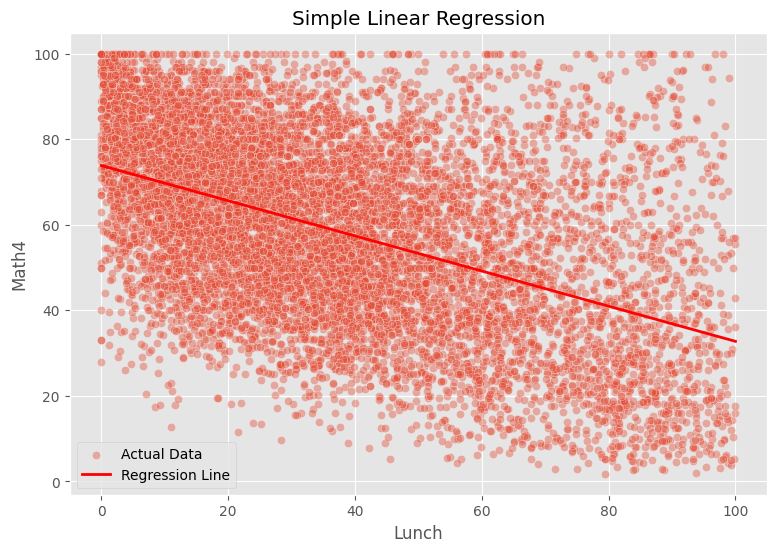

In [22]:
# REGRESSION LINE VISUALIZATION

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=slr_data,
    x='lunch',
    y='math4',
    alpha=0.4,
    label='Actual Data'
)

# Generate regression line
x_line = np.linspace(
    slr_data['lunch'].min(),
    slr_data['lunch'].max(),
    200
)

y_line = slr_model.predict(
    pd.DataFrame({'lunch': x_line})
)

plt.plot(
    x_line,
    y_line,
    color='red',
    linewidth=2,
    label='Regression Line'
)

plt.title('Simple Linear Regression')
plt.xlabel('Lunch')
plt.ylabel('Math4')

plt.legend()
plt.show()

In [23]:
# MODEL EVALUATION

y_pred = slr_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("SIMPLE LINEAR REGRESSION RESULTS")
print("-" * 40)

print("Mean Squared Error:", round(mse, 4))
print("Root Mean Squared Error:", round(rmse, 4))
print("Mean Absolute Error:", round(mae, 4))
print("R2 Score:", round(r2, 4))

SIMPLE LINEAR REGRESSION RESULTS
----------------------------------------
Mean Squared Error: 354.689
Root Mean Squared Error: 18.8332
Mean Absolute Error: 15.2638
R2 Score: 0.2213


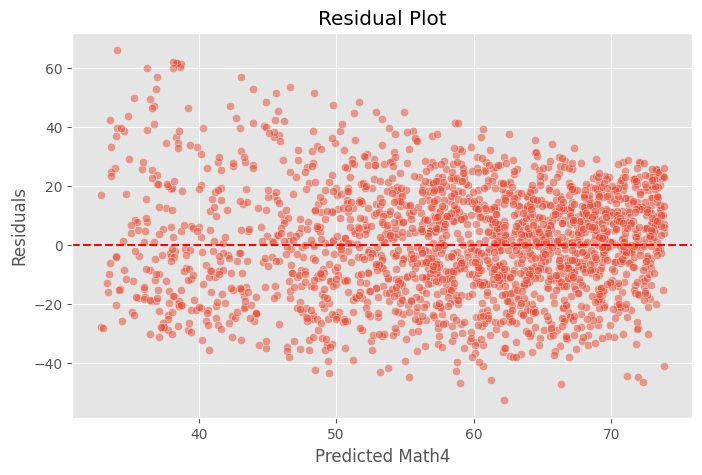

In [24]:
# RESIDUAL ANALYSIS

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_pred,
    y=residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.title('Residual Plot')
plt.xlabel('Predicted Math4')
plt.ylabel('Residuals')

plt.show()